# PL5 — Exercise 2: Two losses, two trainings
### Generative AI · MSc in Artificial Intelligence · Lab 5 

In Exercise 1 you built the masked-LM corruption. Now you write the **loss** of each family and train both models from the **same code**:

* a **decoder** (GPT-style): causal mask, predicts the **next** character at every position;
* an **encoder** (BERT-style): no mask, predicts the **original** character only where the input was corrupted.

| Step | What you do | Time |
|---|---|---|
| 2.1 | read a worked example of `cross_entropy` | 2 min |
| 2.2 | write the two losses (one line each) | 5 min |
| 2.3 | train both models (just run) | ~5–7 min CPU, < 1 min GPU |
| Q | two short questions | 5 min |

**Instructions.** Run the cells in order. Replace each `____` with **one line** of code, then run the `CHECK` cell right after it: ✅ means done. Stuck? Open the 💡 **Hint** — after trying for a minute.

**Names / student numbers:** _…_

### Setup
**Only if PyTorch or matplotlib is not installed** (on Google Colab both are already there): remove the `#` and run the cell, then restart the kernel.

In [6]:
# %pip install matplotlib torch --index-url https://download.pytorch.org/whl/cpu --extra-index-url https://pypi.org/simple

In [7]:
import math, time
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.12.0 | device: cpu


---
## The model and the data (nothing to do — just run)

| | Decoder (GPT, PL2) | Encoder (BERT, today) |
|---|---|---|
| **Mask** | causal: position *t* sees positions ≤ *t* | none: every position sees every position |
| **Input** | the text as it is | the text with ~15% of characters corrupted |
| **Each position predicts** | the **next** character | the **original** character, only where it was corrupted |

The model below is the PL2 Transformer with **one flag**: `causal=True` gives the GPT of PL2, `causal=False` gives a BERT-style encoder.
You do **not** need to change anything in it — just read the `mask` method and run the cell.

In [8]:
class Block(nn.Module):
    def __init__(self, d, n_heads, causal=True):
        super().__init__()
        self.h, self.hd, self.causal = n_heads, d // n_heads, causal
        self.n1, self.n2 = nn.RMSNorm(d), nn.RMSNorm(d)
        self.qkv, self.proj = nn.Linear(d, 3 * d, bias=False), nn.Linear(d, d, bias=False)
        self.ffn = nn.Sequential(nn.Linear(d, 4 * d, bias=False), nn.GELU(), nn.Linear(4 * d, d, bias=False))

    def mask(self, T, device):
        if not self.causal:
            return None                        # encoder: no mask at all -> everyone sees everyone
        i = torch.arange(T, device=device)[:, None]   # row    = query position
        j = torch.arange(T, device=device)[None, :]   # column = key position
        return j <= i                          # decoder: query i may only read keys j <= i

    def forward(self, x):
        B, T, C = x.shape
        h = self.n1(x)
        q, k, v = [t.view(B, T, self.h, self.hd).transpose(1, 2) for t in self.qkv(h).split(C, -1)]
        a = F.scaled_dot_product_attention(q, k, v, attn_mask=self.mask(T, x.device))
        x = x + self.proj(a.transpose(1, 2).reshape(B, T, C))
        return x + self.ffn(self.n2(x))


class Transformer(nn.Module):
    # One architecture, two behaviours: causal LM (causal=True) or masked LM (causal=False).
    def __init__(self, vocab, d=128, n_layers=2, n_heads=4, context=128, causal=True):
        super().__init__()
        self.context = context
        self.tok, self.pos = nn.Embedding(vocab, d), nn.Embedding(context, d)
        self.blocks = nn.ModuleList([Block(d, n_heads, causal) for _ in range(n_layers)])
        self.norm, self.head = nn.RMSNorm(d), nn.Linear(d, vocab, bias=False)
        self.head.weight = self.tok.weight
        for m in self.modules():
            if isinstance(m, (nn.Linear, nn.Embedding)):
                nn.init.normal_(m.weight, 0.0, 0.02)

    def forward(self, idx):                    # idx: (B, T) token ids  ->  logits: (B, T, vocab)
        x = self.tok(idx) + self.pos(torch.arange(idx.size(1), device=idx.device))
        for b in self.blocks:
            x = b(x)
        return self.head(self.norm(x))

print("ok")

ok


In [9]:
with open("data/tiny_shakespeare.txt", encoding="utf-8") as f:
    text = f.read()
chars = sorted(set(text))
MASK = len(chars)                      # one extra id for [MASK]
V = len(chars) + 1
stoi = {c: i for i, c in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: "".join(chars[i] if i < len(chars) else "▁" for i in ids)
data = torch.tensor(encode(text), dtype=torch.long)
split = int(0.9 * len(data))
train_data, val_data = data[:split], data[split:]
CTX, BATCH = 128, 32
STEPS = 800 if device == "cuda" else 500
print(f"V = {V} (including [MASK] = {MASK}), {len(train_data):,} train characters, {STEPS} steps for the GPT")

def get_batch(split, batch=BATCH, context=CTX):
    src = train_data if split == "train" else val_data
    ix = torch.randint(len(src) - context - 1, (batch,))
    x = torch.stack([src[i:i + context] for i in ix])
    y = torch.stack([src[i + 1:i + context + 1] for i in ix])   # y = x shifted one to the left
    return x.to(device), y.to(device)

xb, yb = get_batch("train")
print("x[0]:", repr(decode(xb[0, :50].tolist())))
print("y[0]:", repr(decode(yb[0, :50].tolist())), " <- the same text, one character later")

V = 66 (including [MASK] = 65), 1,003,854 train characters, 500 steps for the GPT
x[0]: 'aith of heart\nTo his most royal person, hither com'
y[0]: 'ith of heart\nTo his most royal person, hither come'  <- the same text, one character later


### The corruption from Exercise 1 (given — just run)
This is the solution of Exercise 1: choose 15% of the positions, replace 80% of them by `[MASK]`, 10% by a random token, keep 10%, and return targets that are `-100` everywhere except at the chosen positions.

In [10]:
def mlm_batch(x, p=0.15):
    x = x.clone()                                   # never modify the caller's tensor
    targets = torch.full_like(x, -100)              # -100 everywhere = "no loss here"
    chosen = torch.rand(x.shape, device=x.device) < p
    r = torch.rand(x.shape, device=x.device)
    to_mask = chosen & (r < 0.8)
    to_random = chosen & (r >= 0.8) & (r < 0.9)

    targets[chosen] = x[chosen]                     # TODO: the ORIGINAL tokens at the chosen positions
    x[to_mask] = MASK
    x[to_random] = torch.randint(0, MASK, (int(to_random.sum()),), device=x.device)
    return x, targets

xc, tg = mlm_batch(xb)
print("original :", repr(decode(xb[0, :60].tolist())))
print("corrupted:", repr(decode(xc[0, :60].tolist())))

original : 'aith of heart\nTo his most royal person, hither come\nEven at '
corrupted: 'ait▁ of hea▁▁\nTo his most▁royal person▁ hithe▁ c▁me▁Even at '


---
## 2.1 — A worked example

`F.cross_entropy` wants **2-D logits** `(N, V)` and **1-D targets** `(N,)`. Our model outputs `(B, T, V)`, so we flatten batch and time together with `reshape`. Targets equal to `-100` are skipped.

In [11]:
B_, T_, V_ = 2, 3, 5
logits_demo = torch.randn(B_, T_, V_)                   # what a model returns: (B, T, V)
targets_demo = torch.tensor([[1, 4, 0], [2, -100, -100]])

loss_demo = F.cross_entropy(logits_demo.reshape(-1, V_),   # (B*T, V) = (6, 5)
                            targets_demo.reshape(-1),      # (B*T,)   = (6,)
                            ignore_index=-100)             # the two -100 entries give no loss
print("logits", tuple(logits_demo.shape), "->", tuple(logits_demo.reshape(-1, V_).shape))
print("targets", tuple(targets_demo.shape), "->", tuple(targets_demo.reshape(-1).shape))
print(f"loss = {loss_demo.item():.3f}  (an average over the 4 positions whose target is not -100)")

logits (2, 3, 5) -> (6, 5)
targets (2, 3) -> (6,)
loss = 2.059  (an average over the 4 positions whose target is not -100)


## 2.2 — Your turn: one line in each function
* **Causal:** the logits of the whole sequence against the shifted targets `yb`.
* **Masked:** the logits of the **corrupted** input against `tg`, ignoring `-100`.


<details><summary>💡 <b>Hint</b> (try first!)</summary>

Copy the pattern of the worked example: `F.cross_entropy(logits.reshape(-1, V), targets.reshape(-1))`. For the masked loss add `ignore_index=-100` (it is actually the default, but writing it makes the intent clear).

</details>

In [12]:
def causal_loss(model, xb, yb):
    logits = model(xb)                       # (B, T, V)
    return F.cross_entropy(logits.reshape(-1, V), yb.reshape(-1))


def mlm_loss(model, xb):
    xc, tg = mlm_batch(xb)                   # corrupted input + targets (-100 almost everywhere)
    logits = model(xc)                       # (B, T, V)
    return F.cross_entropy(logits.reshape(-1, V), tg.reshape(-1), ignore_index=-100)

In [13]:
# CHECK 2.2 — before training, a model that guesses uniformly has loss ≈ ln(V)
torch.manual_seed(0)
xb, yb = get_batch("train")
l_c = causal_loss(Transformer(V, causal=True, context=CTX).to(device), xb, yb).item()
l_m = mlm_loss(Transformer(V, causal=False, context=CTX).to(device), xb).item()
print(f"untrained losses: causal {l_c:.2f} | masked {l_m:.2f} | ln(V) = {math.log(V):.2f}")
assert abs(l_c - math.log(V)) < 0.4, "causal loss of an untrained model should be close to ln(V)"
assert abs(l_m - math.log(V)) < 0.4, "masked loss of an untrained model should be close to ln(V) — did you use tg and ignore_index?"
print("✅ 2.2 OK — you can train")

untrained losses: causal 4.23 | masked 4.21 | ln(V) = 4.19
✅ 2.2 OK — you can train


## 2.3 — Train both models (just run — about 5–7 minutes on a laptop CPU, under a minute on a GPU)
Read the two printed lines first: they are the lecture's "free training signal" argument in numbers.

In [14]:
def train(model, loss_fn, steps=STEPS, lr=2e-3, label=""):
    model.to(device).train()
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.1)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / 50) * 0.5 * (1 + math.cos(math.pi * min(s, steps) / steps)))
    t0, hist = time.time(), []
    for step in range(steps):
        xb, yb = get_batch("train")
        loss = loss_fn(model, xb, yb)
        opt.zero_grad(set_to_none=True); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step()
        if step % 50 == 0:
            hist.append((step, loss.item()))
        if step % 200 == 0:
            print(f"  {label} step {step:5d}  loss {loss.item():.3f}")
    print(f"{label:22s} final loss {loss.item():.3f}  ({time.time() - t0:.0f}s)\n")
    return model, hist

print(f"positions with a gradient per step: causal {BATCH * CTX:,} | masked ~{int(0.15 * BATCH * CTX):,}")
print("so the masked model is trained for 3x more steps, and still sees less signal\n")

torch.manual_seed(1337)
gpt, hist_gpt = train(Transformer(V, causal=True, context=CTX), lambda m, x, y: causal_loss(m, x, y), steps=STEPS, label="causal (GPT-style)")
torch.manual_seed(1337)
bert, hist_bert = train(Transformer(V, causal=False, context=CTX), lambda m, x, y: mlm_loss(m, x), steps=3 * STEPS, label="masked (BERT-style)")

positions with a gradient per step: causal 4,096 | masked ~614
so the masked model is trained for 3x more steps, and still sees less signal

  causal (GPT-style) step     0  loss 4.184
  causal (GPT-style) step   200  loss 2.358
  causal (GPT-style) step   400  loss 2.113
causal (GPT-style)     final loss 2.116  (21s)

  masked (BERT-style) step     0  loss 4.149
  masked (BERT-style) step   200  loss 3.065
  masked (BERT-style) step   400  loss 3.043
  masked (BERT-style) step   600  loss 2.481
  masked (BERT-style) step   800  loss 2.093
  masked (BERT-style) step  1000  loss 1.982
  masked (BERT-style) step  1200  loss 1.759
  masked (BERT-style) step  1400  loss 1.770
masked (BERT-style)    final loss 1.726  (60s)



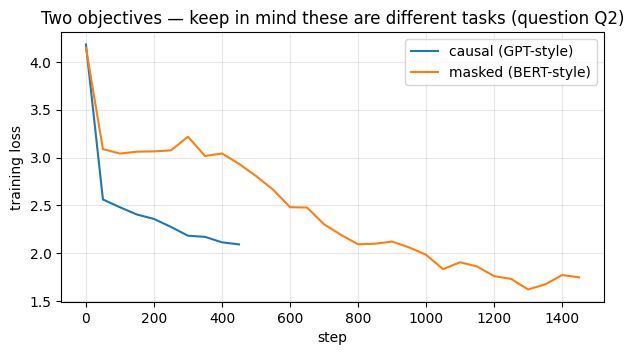

In [15]:
plt.figure(figsize=(7, 3.5))
plt.plot(*zip(*hist_gpt), label="causal (GPT-style)")
plt.plot(*zip(*hist_bert), label="masked (BERT-style)")
plt.xlabel("step"); plt.ylabel("training loss"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Two objectives — keep in mind these are different tasks (question Q2)")
plt.show()

### Save the two models
Exercise 3 asks both models the same question. Saving them now means you will not have to train again.

In [16]:
torch.save(gpt.state_dict(), "gpt.pt")
torch.save(bert.state_dict(), "bert.pt")
print("saved gpt.pt and bert.pt")

saved gpt.pt and bert.pt


---
## Questions

**Q1.** Fill in the two fractions below, run the cell, then complete the sentence: *"Per training step, the causal model gets a gradient at ____% of the positions and the masked model at about ____%. This is the lecture's ______ argument for why decoder-only won."*

In [17]:
frac_causal = 1.0     # TODO: fraction of positions that produce a loss in the causal model (a number between 0 and 1)
frac_masked = 0.15    # TODO: same for the masked model
print(f"causal {frac_causal:.0%} | masked {frac_masked:.0%} | ratio {frac_causal / frac_masked:.1f}x")

causal 100% | masked 15% | ratio 6.7x


In [18]:
# CHECK Q1
assert abs(frac_causal - 1.0) < 1e-6, "every position of the causal model predicts the next character"
assert 0.13 <= frac_masked <= 0.17, "only the chosen positions (p = 0.15) have a target"
print("✅ Q1 OK")

✅ Q1 OK


**Q2.** Look at the plot. Can you conclude that the model with the lower final loss is the better model? *(choose one and justify in one sentence)*
- (A) yes, a lower loss always means a better model;
- (B) no: the two losses measure **different tasks** — next character from the left vs. a hidden character from both sides, on different positions;
- (C) no, because the two models have different numbers of parameters.

**Your answers:**

Q1: Per training step, the causal model gets a gradient at 100% of the positions and the masked model at about 15%. This is the lecture's "free training signal" argument for why decoder-only won.

Q2: (B). The two models are evaluated on completely different tasks and distributions: next-token prediction from left-to-right context on all tokens vs. masked-token recovery from bidirectional context on 15% of tokens, so their losses cannot be directly compared.